# ¿Qué estadísticas de un partido influyen más en la probabilidad de ganar?
**Trabajo práctico de Análisis de Datos** · Datos: *football-data.co.uk* (Premier League, La Liga, Serie A, Bundesliga y Ligue 1, temporadas 2000/01 – 2024/25)

**Índice:** 3.1 Carga y exploración · 3.2 Pregunta de investigación · 3.3 Transformaciones y resumen estadístico · 3.4 Análisis gráfico · 3.5 Modelado (qué estadísticas pesan más) · Respuesta final y limitaciones

In [1]:
import os, warnings
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, pearsonr
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEMILLA = 42
RUTA_CSV = "footballdatacouk_leagues_games_results_2000_2024__1_.csv"
DIR_SALIDA = "graficos"
os.makedirs(DIR_SALIDA, exist_ok=True)

# En Google Colab: si el CSV no está en el entorno, se sube a mano
if not os.path.exists(RUTA_CSV):
    from google.colab import files
    RUTA_CSV = next(iter(files.upload()))

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelsize": 11})

def guardar_figura(fig, nombre):
    """Exporta la figura como PNG (300 dpi) para el informe y la muestra."""
    fig.savefig(os.path.join(DIR_SALIDA, nombre + ".png"), dpi=300, bbox_inches="tight")
    plt.show()

## 3.1 Carga y exploración inicial
### a) Primeras y últimas filas

In [2]:
# 3.1 a) Carga y primeras / últimas filas
df = pd.read_csv(RUTA_CSV)
display(df.head())
display(df.tail())

,Season,League,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,Bundesliga,2000-08-11,Dortmund,Hansa Rostock,1,0,H,0.0,0.0,D,17.0,5.0,7.0,2.0,7.0,3.0,25.0,19.0,1.0,5.0,0.0,0.0
1,2000/01,Bundesliga,2000-08-12,Bayern Munich,Hertha,4,1,H,1.0,0.0,H,14.0,11.0,6.0,5.0,4.0,9.0,13.0,12.0,1.0,0.0,0.0,0.0
2,2000/01,Bundesliga,2000-08-12,Freiburg,Stuttgart,4,0,H,2.0,0.0,H,15.0,18.0,7.0,5.0,4.0,7.0,22.0,17.0,1.0,1.0,0.0,0.0
3,2000/01,Bundesliga,2000-08-12,Hamburg,Munich 1860,2,2,D,2.0,2.0,D,18.0,9.0,5.0,7.0,5.0,3.0,0.0,0.0,2.0,2.0,0.0,1.0
4,2000/01,Bundesliga,2000-08-12,Kaiserslautern,Bochum,0,1,A,0.0,0.0,D,11.0,5.0,2.0,2.0,5.0,5.0,9.0,8.0,1.0,0.0,0.0,0.0


,Season,League,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
44952,2024/25,Serie A,2025-05-25,Empoli,Verona,1,2,A,1.0,1.0,D,14.0,5.0,5.0,2.0,13.0,1.0,10.0,29.0,2.0,2.0,0.0,0.0
44953,2024/25,Serie A,2025-05-25,Lazio,Lecce,0,1,A,0.0,1.0,A,26.0,9.0,7.0,3.0,14.0,4.0,11.0,11.0,2.0,3.0,1.0,1.0
44954,2024/25,Serie A,2025-05-25,Torino,Roma,0,2,A,0.0,1.0,A,11.0,15.0,4.0,5.0,2.0,1.0,15.0,11.0,1.0,1.0,0.0,0.0
44955,2024/25,Serie A,2025-05-25,Udinese,Fiorentina,2,3,A,1.0,0.0,H,12.0,25.0,3.0,11.0,2.0,8.0,15.0,6.0,3.0,2.0,1.0,0.0
44956,2024/25,Serie A,2025-05-25,Venezia,Juventus,2,3,A,1.0,2.0,A,12.0,15.0,5.0,5.0,6.0,6.0,10.0,18.0,1.0,2.0,0.0,0.0


### b) Estructura del dataset

In [3]:
# 3.1 b) Estructura: dimensiones, tipos y cobertura
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas\n")
print(df.dtypes.to_string())

fechas = pd.to_datetime(df["MatchDate"])
print(f"\nCobertura temporal: {fechas.min().date()} a {fechas.max().date()}")
print(f"Temporadas: {df['Season'].nunique()} ({df['Season'].min()} a {df['Season'].max()})")
print(f"Ligas: {sorted(df['League'].unique())}")
print(f"Equipos distintos: {pd.concat([df['HomeTeam'], df['AwayTeam']]).nunique()}")
print("\nPartidos por liga:")
print(df["League"].value_counts().to_string())

Dimensiones: 44,957 filas x 23 columnas

Season                   str
League                   str
MatchDate                str
HomeTeam                 str
AwayTeam                 str
FullTimeHomeGoals      int64
FullTimeAwayGoals      int64
FullTimeResult           str
HalfTimeHomeGoals    float64
HalfTimeAwayGoals    float64
HalfTimeResult           str
HomeShots            float64
AwayShots            float64
HomeShotsOnTarget    float64
AwayShotsOnTarget    float64
HomeCorners          float64
AwayCorners          float64
HomeFouls            float64
AwayFouls            float64
HomeYellowCards      float64
AwayYellowCards      float64
HomeRedCards         float64
AwayRedCards         float64

Cobertura temporal: 2000-07-28 a 2025-05-25
Temporadas: 25 (2000/01 a 2024/25)
Ligas: ['Bundesliga', 'La Liga', 'Ligue 1', 'Premier League', 'Serie A']
Equipos distintos: 217

Partidos por liga:
League
La Liga           9500
Premier League    9500
Serie A           9204
Ligue 1           91

### c) Calidad de los datos

In [4]:
# 3.1 c) Calidad: nulos, duplicados y estadísticas descriptivas
nulos = pd.DataFrame({"nulos": df.isnull().sum(), "% nulos": (df.isnull().mean() * 100).round(1)})
display(nulos[nulos["nulos"] > 0])

print("Duplicados (fila completa):", df.duplicated().sum())
print("Duplicados (fecha + local + visitante):", df.duplicated(["MatchDate", "HomeTeam", "AwayTeam"]).sum())

display(df.describe().T.round(2))

,nulos,% nulos
HalfTimeHomeGoals,4,0.0
HalfTimeAwayGoals,4,0.0
HalfTimeResult,4,0.0
HomeShots,5580,12.4
AwayShots,5580,12.4
HomeShotsOnTarget,6498,14.5
AwayShotsOnTarget,6498,14.5
HomeCorners,5955,13.2
AwayCorners,5955,13.2
HomeFouls,6337,14.1


Duplicados (fila completa): 0
Duplicados (fecha + local + visitante): 0

,count,mean,std,min,25%,50%,75%,max
FullTimeHomeGoals,44957.0,1.53,1.28,0.0,1.0,1.0,2.0,10.0
FullTimeAwayGoals,44957.0,1.16,1.13,0.0,0.0,1.0,2.0,9.0
HalfTimeHomeGoals,44953.0,0.68,0.83,0.0,0.0,0.0,1.0,6.0
HalfTimeAwayGoals,44953.0,0.51,0.72,0.0,0.0,0.0,1.0,6.0
HomeShots,39377.0,13.73,5.17,0.0,10.0,13.0,17.0,46.0
AwayShots,39377.0,11.02,4.58,0.0,8.0,11.0,14.0,39.0
HomeShotsOnTarget,38459.0,5.25,2.83,0.0,3.0,5.0,7.0,24.0
AwayShotsOnTarget,38459.0,4.17,2.46,0.0,2.0,4.0,6.0,20.0
HomeCorners,39002.0,5.67,2.98,0.0,4.0,5.0,7.0,26.0
AwayCorners,39002.0,4.47,2.60,0.0,3.0,4.0,6.0,19.0


In [5]:
# ¿Los nulos son aleatorios? % de partidos SIN estadísticas de tiros, por liga y temporada
df["sin_tiros"] = df["HomeShots"].isna()
patron = (df.pivot_table(index="Season", columns="League", values="sin_tiros", aggfunc="mean") * 100).round(0)
display(patron.head(7))
print("A partir de 2005/06 el % de partidos sin estadísticas es:")
print((df[df["Season"] >= "2005/06"].groupby("League")["sin_tiros"].mean() * 100).round(2).to_string())

League,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
Season,,,,,
2000/01,0.0,100.0,100.0,0.0,100.0
2001/02,0.0,100.0,100.0,0.0,100.0
2002/03,100.0,100.0,100.0,0.0,100.0
2003/04,0.0,100.0,100.0,0.0,100.0
2004/05,0.0,100.0,100.0,0.0,100.0
2005/06,0.0,0.0,0.0,0.0,4.0
2006/07,0.0,0.0,0.0,0.0,0.0


A partir de 2005/06 el % de partidos sin estadísticas es:
League
Bundesliga        0.02
La Liga           0.00
Ligue 1           0.03
Premier League    0.00
Serie A           0.20

#### Comentario sobre la calidad de los datos
- **Estructura:** 44.957 partidos × 23 columnas, de 5 ligas europeas y 25 temporadas (28/07/2000 – 25/05/2025). Cada fila es un partido. Hay goles y resultado (completos) y seis estadísticas de juego por equipo: tiros, tiros al arco, corners, faltas, amarillas y rojas.
- **Tipos de dato:** `MatchDate` está como texto y habrá que convertirla a fecha. El resto de los tipos es coherente.
- **Duplicados:** no hay (ni filas completas ni repetidos por fecha + local + visitante).
- **Nulos:** las estadísticas de juego tienen entre 12,4 % y 14,5 % de faltantes. **No son aleatorios:** La Liga, Ligue 1 y Serie A no registran estadísticas entre 2000/01 y 2004/05 (100 % de nulos), y la Bundesliga tampoco en 2002/03. Desde 2005/06 la cobertura es casi completa. La Premier League prácticamente no tiene nulos.
- **Estadísticas descriptivas:** el local anota más que el visitante (1,53 vs. 1,16 goles) y tira más (13,7 vs. 11,0 tiros), lo que anticipa una ventaja de localía. Hay dos partidos con 0 faltas para ambos equipos, probablemente un error de carga, con impacto despreciable.
- **Ausencias relevantes:** la base **no incluye posesión**, goles esperados (xG), pases ni duelos. Es una limitación importante, ya que la posesión es una de las estadísticas más citadas al hablar de fútbol, y queda fuera de lo que se puede responder con estos datos.

## 3.2 Pregunta de investigación

**a) ¿Cuál es la pregunta?**
¿Qué estadísticas de un partido (tiros al arco, tiros fuera del arco, corners, faltas, tarjetas y jugar de local) se asocian más con la probabilidad de que un equipo gane, en las cinco grandes ligas europeas entre 2000/01 y 2024/25?

**b) ¿Por qué vale la pena responderla?**
En el fútbol conviven muchas ideas sobre qué hace ganar: "el que más tira gana", "la localía pesa", "los equipos que sacan más corners dominan", "ser agresivo ayuda". Cuantificar cuáles de esas estadísticas realmente se relacionan con el resultado permite distinguir indicadores informativos de simple volumen de juego, algo útil para el análisis de rendimiento de equipos y para evaluar qué métricas conviene seguir.

**c) ¿Qué respuesta encontraron?**
*(Se completa al final del notebook, en la sección "Respuesta a la pregunta de investigación").*

## 3.3 Transformaciones y resumen estadístico
### a) Transformaciones justificadas

In [6]:
# TRANSFORMACIÓN 1 — Convertir tipos y crear columnas de tiempo
df["MatchDate"] = pd.to_datetime(df["MatchDate"])
df["anio_inicio"] = df["Season"].str[:4].astype(int)
print(df[["MatchDate", "Season", "anio_inicio"]].dtypes.to_string())

MatchDate      datetime64[us]
Season                    str
anio_inicio             int64

**Transformación 1: convertir `MatchDate` a fecha y crear `anio_inicio`.** La fecha venía como texto; como fecha se puede ordenar y filtrar cronológicamente. `anio_inicio` (primer año de la temporada) permite agrupar y comparar por época.

In [7]:
# TRANSFORMACIÓN 2 — Filtrar partidos sin estadísticas de juego
COLS_STATS = ["HomeShots", "AwayShots", "HomeShotsOnTarget", "AwayShotsOnTarget",
              "HomeCorners", "AwayCorners", "HomeFouls", "AwayFouls",
              "HomeYellowCards", "AwayYellowCards", "HomeRedCards", "AwayRedCards"]
completo = df.dropna(subset=COLS_STATS).copy()

# Coherencia interna: tiros al arco no pueden superar tiros totales
incoherentes = ((completo["HomeShotsOnTarget"] > completo["HomeShots"]) |
                (completo["AwayShotsOnTarget"] > completo["AwayShots"]))
print("Filas incoherentes (tiros al arco > tiros totales):", int(incoherentes.sum()))
completo = completo[~incoherentes].copy()

print(f"Partidos totales: {len(df):,} | con estadísticas completas: {len(completo):,} "
      f"({len(completo)/len(df):.1%})")
print(f"Temporadas del subconjunto: {completo['Season'].min()} a {completo['Season'].max()}")
display(pd.DataFrame({"total": df["League"].value_counts(),
                      "usados": completo["League"].value_counts()}))

Filas incoherentes (tiros al arco > tiros totales): 3
Partidos totales: 44,957 | con estadísticas completas: 37,694 (83.8%)
Temporadas del subconjunto: 2000/01 a 2024/25

,total,usados
League,,
Bundesliga,7650,6425
La Liga,9500,7600
Ligue 1,9103,6588
Premier League,9500,9497
Serie A,9204,7584


**Transformación 2: quedarse solo con partidos con estadísticas completas.** El análisis de la pregunta necesita las seis estadísticas de ambos equipos, y ya vimos que los nulos son estructurales (ciertas ligas y años sin registro). Imputarlos sería inventar datos de partidos enteros, por lo que se descartan: quedan **37.694 partidos (83,8 %)**. Además se eliminaron 3 filas incoherentes (más tiros al arco que tiros totales). Consecuencia a tener en cuenta: antes de 2005/06 el subconjunto está formado casi solo por Premier League y Bundesliga, de modo que las conclusiones sobre estadísticas reflejan sobre todo las temporadas 2005/06 en adelante. Los gráficos de resultados puros (que no requieren estadísticas) usan los 44.957 partidos.

In [8]:
# TRANSFORMACIÓN 3 — Pasar a formato "equipo-partido" y crear variables derivadas
# Cada partido genera 2 filas (perspectiva del local y del visitante); las estadísticas
# se expresan como diferencia (propio - rival), porque ganar es un fenómeno relativo.
ESTADS = {"Shots": "tiros", "ShotsOnTarget": "tiros_al_arco", "Corners": "corners",
          "Fouls": "faltas", "YellowCards": "amarillas", "RedCards": "rojas"}

def lado(d, propio, rival, es_local):
    out = pd.DataFrame({"partido_id": d.index, "liga": d["League"].values,
                        "temporada": d["Season"].values, "equipo": d[f"{propio}Team"].values,
                        "es_local": es_local,
                        "goles_favor": d[f"FullTime{propio}Goals"].values,
                        "goles_contra": d[f"FullTime{rival}Goals"].values})
    for orig, nuevo in ESTADS.items():
        out[nuevo] = d[f"{propio}{orig}"].values
        out[nuevo + "_rival"] = d[f"{rival}{orig}"].values
    return out

largo = pd.concat([lado(completo, "Home", "Away", 1), lado(completo, "Away", "Home", 0)],
                  ignore_index=True)

# Tiros fuera del arco = tiros totales - tiros al arco (evita usar dos variables casi redundantes)
largo["tiros_fuera"] = largo["tiros"] - largo["tiros_al_arco"]
largo["tiros_fuera_rival"] = largo["tiros_rival"] - largo["tiros_al_arco_rival"]
for v in ["tiros", "tiros_al_arco", "tiros_fuera", "corners", "faltas", "amarillas", "rojas"]:
    largo["dif_" + v] = largo[v] - largo[v + "_rival"]

largo["resultado"] = np.select([largo.goles_favor > largo.goles_contra,
                                largo.goles_favor == largo.goles_contra],
                               ["Victoria", "Empate"], default="Derrota")
largo["victoria"] = (largo["resultado"] == "Victoria").astype(int)   # variable objetivo
largo["puntos"] = largo["resultado"].map({"Victoria": 3, "Empate": 1, "Derrota": 0})

print(f"Observaciones equipo-partido: {len(largo):,} ({largo['partido_id'].nunique():,} partidos)")
print(f"Tasa base de victoria: {largo['victoria'].mean():.1%} | empates: {(largo['resultado']=='Empate').mean():.1%}")
display(largo[["equipo", "es_local", "resultado", "tiros_al_arco", "tiros_al_arco_rival",
               "dif_tiros_al_arco", "dif_corners", "dif_faltas"]].head())

Observaciones equipo-partido: 75,388 (37,694 partidos)
Tasa base de victoria: 37.3% | empates: 25.5%

,equipo,es_local,resultado,tiros_al_arco,tiros_al_arco_rival,dif_tiros_al_arco,dif_corners,dif_faltas
0,Dortmund,1,Victoria,7.0,2.0,5.0,4.0,6.0
1,Bayern Munich,1,Victoria,6.0,5.0,1.0,-5.0,1.0
2,Freiburg,1,Victoria,7.0,5.0,2.0,-3.0,5.0
3,Hamburg,1,Empate,5.0,7.0,-2.0,2.0,0.0
4,Kaiserslautern,1,Derrota,2.0,2.0,0.0,0.0,1.0


**Transformación 3: formato "equipo-partido" y variables derivadas.** Cada partido se desdobla en dos filas (visión del local y del visitante), porque la pregunta es sobre *un equipo* que gana o no. Se crean:
- `resultado` (Victoria / Empate / Derrota), `victoria` (1 si ganó, 0 si empató o perdió: variable objetivo) y `puntos` (3-1-0);
- `tiros_fuera` = tiros − tiros al arco, para no usar dos variables casi redundantes;
- **diferencias propio − rival** (`dif_*`), porque ganar depende de cuánto se supera al rival y no del valor absoluto: 15 tiros significan algo distinto frente a un rival que tiró 5 o 25.

### b) Estadísticos de resumen agrupados (`groupby`)

In [9]:
# 3.3 b) GROUPBY 1 — Resultados por liga (todas las temporadas, 44.957 partidos)
df["goles_totales"] = df["FullTimeHomeGoals"] + df["FullTimeAwayGoals"]
por_liga = df.groupby("League").agg(
    partidos=("FullTimeResult", "size"),
    pct_local=("FullTimeResult", lambda s: (s == "H").mean() * 100),
    pct_empate=("FullTimeResult", lambda s: (s == "D").mean() * 100),
    pct_visitante=("FullTimeResult", lambda s: (s == "A").mean() * 100),
    goles_por_partido=("goles_totales", "mean"),
)
display(por_liga.round(1))

,partidos,pct_local,pct_empate,pct_visitante,goles_por_partido
League,,,,,
Bundesliga,7650,45.8,24.7,29.5,2.9
La Liga,9500,47.0,25.2,27.7,2.7
Ligue 1,9103,45.3,27.7,27.1,2.5
Premier League,9500,45.8,24.7,29.5,2.7
Serie A,9204,44.6,27.1,28.3,2.7


**Interpretación.** La ventaja de jugar de local aparece en las cinco ligas: el local gana entre 44,6 % (Serie A) y 47,0 % (La Liga) de los partidos, y el visitante entre 27,1 % y 29,5 %. Las ligas se parecen bastante entre sí (diferencias de 2 a 3 puntos porcentuales). Ligue 1 y Serie A son las que más empatan (27,7 % y 27,1 %), y la Bundesliga la de más goles por partido (2,9). Para la pregunta, esto indica que la localía es un factor general y no propio de una liga.

In [10]:
# 3.3 b) GROUPBY 2 — Promedio de cada estadística según el resultado del equipo
VARS = ["tiros_al_arco", "tiros_fuera", "corners", "faltas", "amarillas", "rojas"]
por_resultado = (largo.groupby("resultado")[VARS].mean()
                      .reindex(["Victoria", "Empate", "Derrota"]))
display(por_resultado.round(2))

# Diferencia relativa Victoria vs Derrota
print("Cociente Victoria / Derrota:")
print((por_resultado.loc["Victoria"] / por_resultado.loc["Derrota"]).round(2).to_string())

,tiros_al_arco,tiros_fuera,corners,faltas,amarillas,rojas
resultado,,,,,,
Victoria,6.00,7.79,5.19,13.57,1.84,0.06
Empate,4.33,7.84,5.15,14.17,2.10,0.11
Derrota,3.70,7.44,4.92,13.87,2.09,0.16


Cociente Victoria / Derrota:
tiros_al_arco    1.62
tiros_fuera      1.05
corners          1.05
faltas           0.98
amarillas        0.88
rojas            0.38

**Interpretación.** De todas las estadísticas, solo los **tiros al arco** separan claramente a los equipos según el resultado: 6,00 por partido en victorias, 4,33 en empates y 3,70 en derrotas (cociente victoria/derrota de 1,62). Los tiros fuera, corners y faltas casi no cambian entre resultados (cocientes entre 0,98 y 1,05). Las **rojas** muestran un patrón claro: 0,06 por partido en victorias contra 0,16 en derrotas, es decir que perder se asocia con casi tres veces más expulsiones.

In [11]:
# 3.3 b) GROUPBY 3 — Ventaja de localía: tasa de victoria según juegue de local o visitante
loc = largo.groupby("es_local").agg(partidos=("victoria", "size"),
                                    pct_victoria=("victoria", lambda s: s.mean() * 100),
                                    puntos_por_partido=("puntos", "mean"),
                                    dif_tiros_al_arco=("dif_tiros_al_arco", "mean"))
loc.index = ["Visitante", "Local"]
display(loc.round(2))

,partidos,pct_victoria,puntos_por_partido,dif_tiros_al_arco
Visitante,37694,29.15,1.13,-1.08
Local,37694,45.38,1.62,1.08


**Interpretación.** Jugar de local se asocia con ganar el 45,4 % de las veces contra 29,2 % de visitante, y con 1,62 puntos por partido contra 1,13. Además, el local supera al rival en +1,08 tiros al arco por partido, mientras que el visitante queda en −1,08. Queda planteado un punto que el modelo debe aclarar: si la ventaja de localía se explica solo porque el local tira más, o si persiste aun a igualdad de tiros.

## 3.4 Análisis gráfico
Los gráficos se exportan como PNG a 300 dpi en la carpeta `graficos/` para incluirlos en el informe.

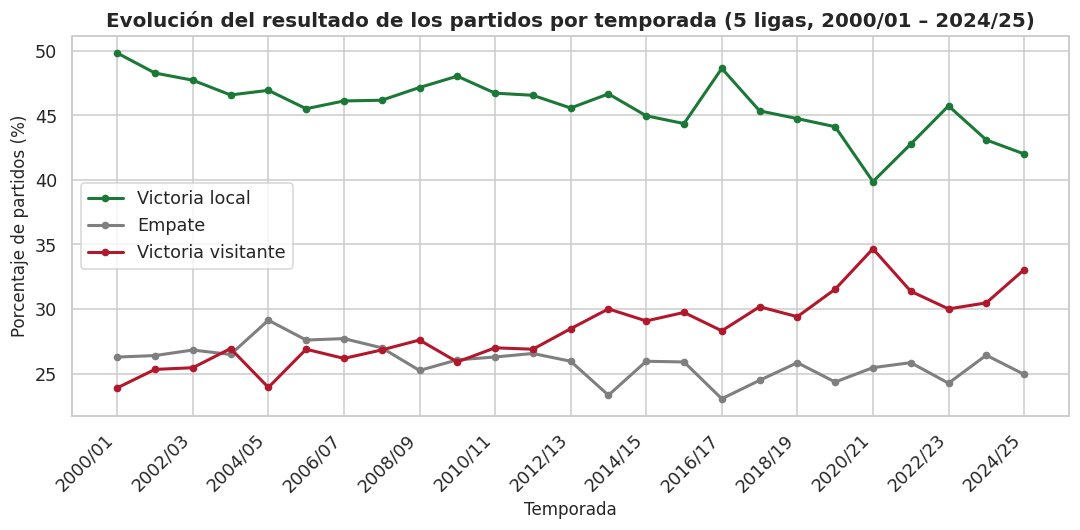

Local 2000/01-2004/05: 47.9 % | 2020/21-2024/25: 42.7 %
Mínimo victoria local: 2020/21 39.9 %

In [12]:
# GRÁFICO 1 (evolución temporal) — % de resultados por temporada
t = (df.groupby("Season")["FullTimeResult"].value_counts(normalize=True).unstack() * 100)
fig, ax = plt.subplots(figsize=(10, 5))
for col, nom, c in [("H", "Victoria local", "#1b7837"), ("D", "Empate", "#7f7f7f"), ("A", "Victoria visitante", "#b2182b")]:
    ax.plot(t.index, t[col], marker="o", ms=4, lw=2, color=c, label=nom)
ax.set_xticks(range(0, len(t), 2))
ax.set_xticklabels(t.index[::2], rotation=45, ha="right")
ax.set_xlabel("Temporada")
ax.set_ylabel("Porcentaje de partidos (%)")
ax.set_title("Evolución del resultado de los partidos por temporada (5 ligas, 2000/01 – 2024/25)")
ax.legend()
fig.tight_layout()
guardar_figura(fig, "g1_evolucion_resultados")
print("Local 2000/01-2004/05:", t.loc["2000/01":"2004/05", "H"].mean().round(1), "% | 2020/21-2024/25:", t.loc["2020/21":"2024/25", "H"].mean().round(1), "%")
print("Mínimo victoria local:", t["H"].idxmin(), t["H"].min().round(1), "%")

**Interpretación (Gráfico 1: evolución temporal).** La victoria local fue cayendo: del 47,9 % de los partidos en 2000/01–2004/05 al 42,7 % en 2020/21–2024/25, con un mínimo de 39,9 % en 2020/21, mientras que las victorias visitantes subieron del 24 % a un 30–35 %. Los empates se mantienen estables (entre 23 % y 29 %). La temporada 2020/21 se jugó en buena parte sin público por la pandemia, por lo que ese mínimo es consistente con la idea de que la afición contribuye a la ventaja local. Es una hipótesis razonable pero no puede probarse con estos datos. En todo caso, la ventaja de localía existe pero se fue reduciendo con los años.

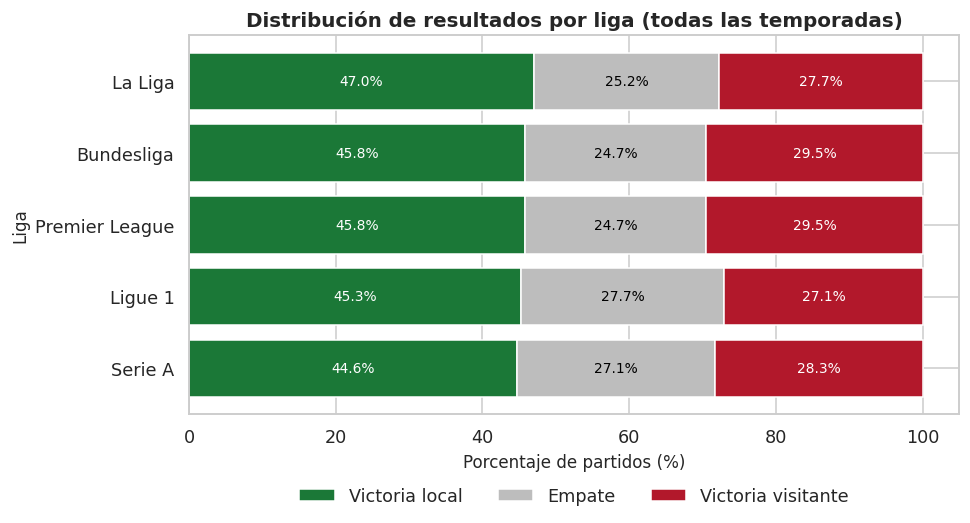

In [13]:
# GRÁFICO 2 (comparación entre categorías) — barras apiladas: resultado por liga
tabla = (pd.crosstab(df["League"], df["FullTimeResult"], normalize="index") * 100)[["H", "D", "A"]]
tabla = tabla.sort_values("H", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
izq = np.zeros(len(tabla))
for col, nom, c in [("H", "Victoria local", "#1b7837"), ("D", "Empate", "#bdbdbd"), ("A", "Victoria visitante", "#b2182b")]:
    ax.barh(tabla.index, tabla[col], left=izq, color=c, label=nom, edgecolor="white")
    for i, v in enumerate(tabla[col]):
        ax.text(izq[i] + v / 2, i, f"{v:.1f}%", ha="center", va="center", color="white" if col != "D" else "black", fontsize=9)
    izq += tabla[col].values
ax.invert_yaxis()
ax.set_xlabel("Porcentaje de partidos (%)")
ax.set_ylabel("Liga")
ax.set_title("Distribución de resultados por liga (todas las temporadas)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
fig.tight_layout()
guardar_figura(fig, "g2_resultados_por_liga")

**Interpretación (Gráfico 2: comparación entre ligas).** En todas las ligas el resultado más frecuente es la victoria local, seguida de la visitante y luego el empate. La Liga es la más favorable al local (47,0 %) y Serie A la menos (44,6 %); Premier League y Bundesliga tienen más victorias visitantes (29,5 %) y Ligue 1 y Serie A más empates. Las diferencias entre ligas son chicas, por lo que tiene sentido analizar las cinco juntas.

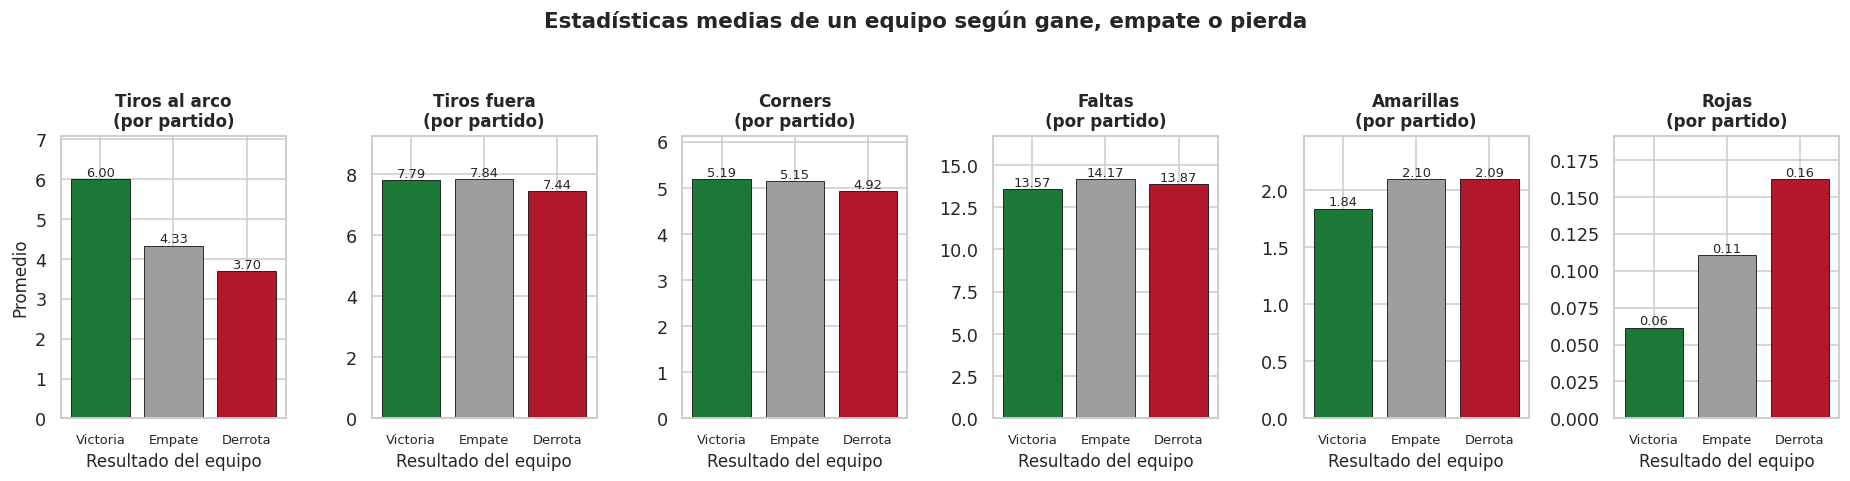

In [14]:
# GRÁFICO 3 (comparación entre categorías) — estadísticas medias según el resultado
etiq = {"tiros_al_arco": "Tiros al arco\n(por partido)", "tiros_fuera": "Tiros fuera\n(por partido)",
        "corners": "Corners\n(por partido)", "faltas": "Faltas\n(por partido)",
        "amarillas": "Amarillas\n(por partido)", "rojas": "Rojas\n(por partido)"}
colores = {"Victoria": "#1b7837", "Empate": "#9e9e9e", "Derrota": "#b2182b"}
fig, axes = plt.subplots(1, 6, figsize=(17, 4.2))
for ax, v in zip(axes, VARS):
    vals = por_resultado[v]
    ax.bar(vals.index, vals.values, color=[colores[i] for i in vals.index], edgecolor="black", lw=0.5)
    for i, x in enumerate(vals.values):
        ax.text(i, x, f"{x:.2f}", ha="center", va="bottom", fontsize=8.5)
    ax.set_title(etiq[v], fontsize=11)
    ax.set_xlabel("Resultado del equipo")
    ax.set_ylim(0, vals.max() * 1.18)
    ax.tick_params(axis="x", labelsize=8.5)
axes[0].set_ylabel("Promedio")
fig.suptitle("Estadísticas medias de un equipo según gane, empate o pierda", fontsize=14, fontweight="bold", y=1.04)
fig.tight_layout()
guardar_figura(fig, "g3_estadisticas_por_resultado")

**Interpretación (Gráfico 3: estadísticas medias según el resultado).** Los equipos que ganan tiran al arco bastante más que los que pierden (6,00 vs. 3,70), pero **no tiran mucho más en total**: los tiros fuera del arco son prácticamente iguales (7,79 vs. 7,44). En otras palabras, lo que distingue a quien gana es la *calidad* del tiro (que sea al arco) y no la cantidad. Los corners y las faltas casi no varían. Las amarillas son algo menores en las victorias (1,84 vs. 2,09) y las rojas son mucho menos frecuentes (0,06 vs. 0,16).

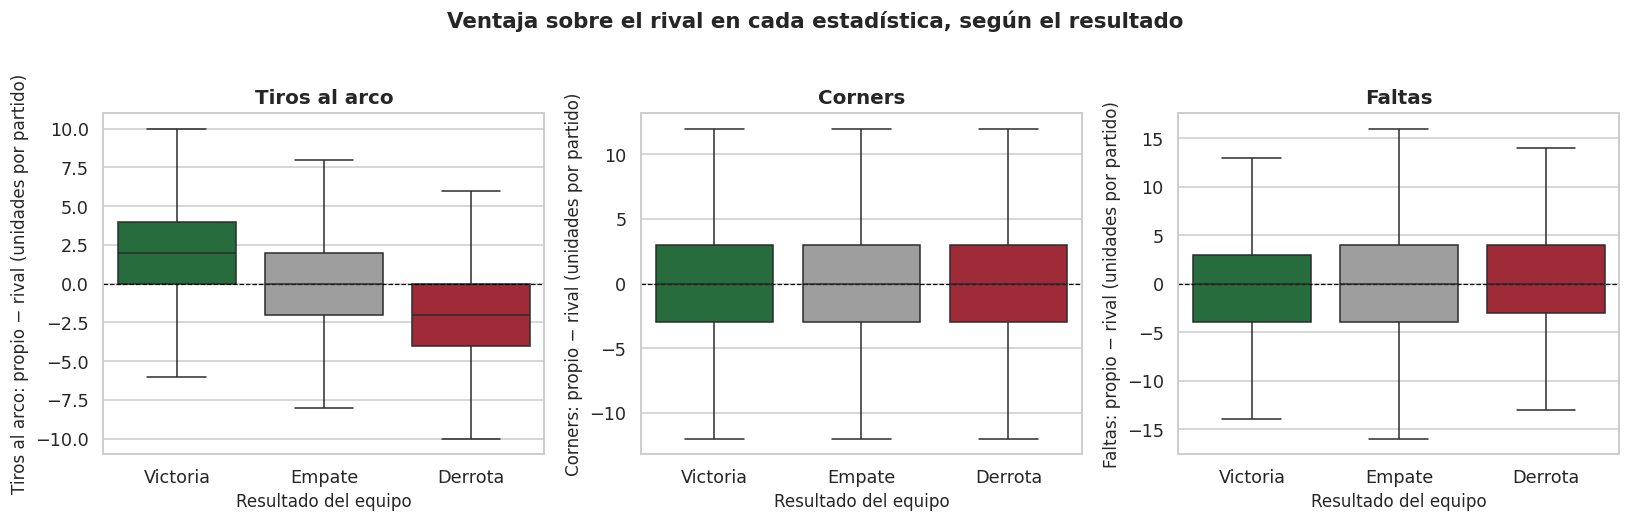

           dif_tiros_al_arco  dif_corners  dif_faltas
resultado                                            
Victoria                 2.0          0.0         0.0
Empate                   0.0          0.0         0.0
Derrota                 -2.0          0.0         0.0

In [15]:
# GRÁFICO 4 (distribución) — diferencia con el rival según el resultado
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
orden = ["Victoria", "Empate", "Derrota"]
for ax, (v, tit) in zip(axes, [("dif_tiros_al_arco", "Tiros al arco"), ("dif_corners", "Corners"), ("dif_faltas", "Faltas")]):
    sns.boxplot(data=largo, x="resultado", y=v, order=orden, hue="resultado", hue_order=orden,
                palette=colores, dodge=False, showfliers=False, ax=ax)
    if ax.get_legend(): ax.get_legend().remove()
    ax.axhline(0, color="black", lw=0.8, ls="--")
    ax.set_title(tit)
    ax.set_xlabel("Resultado del equipo")
    ax.set_ylabel(f"{tit}: propio − rival (unidades por partido)")
fig.suptitle("Ventaja sobre el rival en cada estadística, según el resultado", fontsize=14, fontweight="bold", y=1.03)
fig.tight_layout()
guardar_figura(fig, "g4_boxplots_diferencias")
print(largo.groupby("resultado")[["dif_tiros_al_arco", "dif_corners", "dif_faltas"]].median().reindex(orden).round(2))

**Interpretación (Gráfico 4: distribución de las diferencias con el rival).** La mediana de la diferencia de tiros al arco es +2 en victorias, 0 en empates y −2 en derrotas, con cajas que casi no se solapan: es la única estadística con una separación visible. En corners y faltas las tres cajas son prácticamente idénticas y centradas en 0, de modo que saber quién sacó más corners o cometió más faltas dice muy poco sobre quién ganó. (Los valores extremos no se dibujan para facilitar la lectura.)

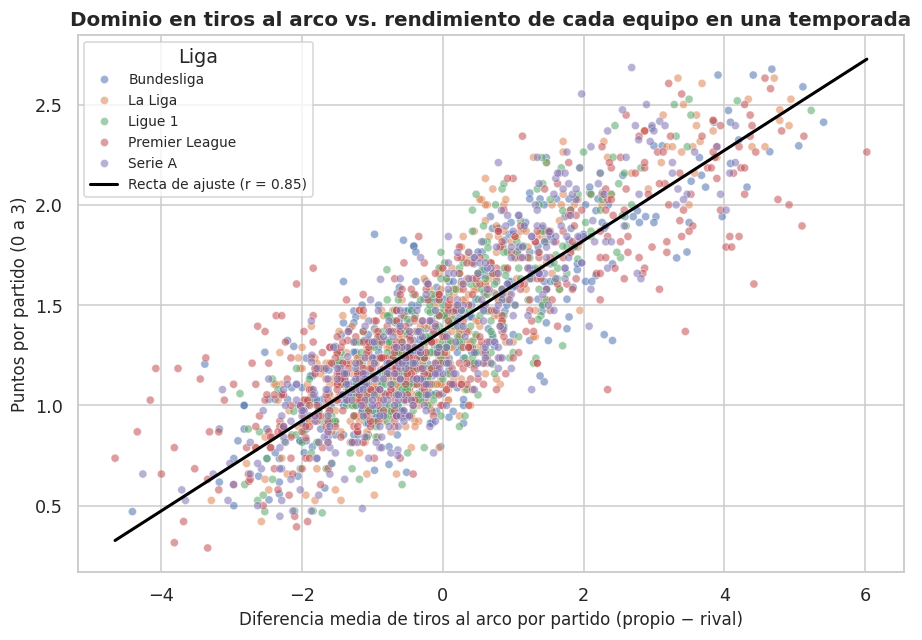

Equipo-temporadas: 2034 | r de Pearson = 0.845 (p < 0.0001) | pendiente = 0.22 puntos por partido por cada +1 tiro al arco de diferencia

In [16]:
# GRÁFICO 5 (relación entre dos variables) — rendimiento de equipos por temporada
ts = (largo.groupby(["liga", "temporada", "equipo"])
           .agg(partidos=("victoria", "size"), ppp=("puntos", "mean"),
                dif_tiros_al_arco=("dif_tiros_al_arco", "mean"))
           .query("partidos >= 25").reset_index())
r, p = pearsonr(ts["dif_tiros_al_arco"], ts["ppp"])
pend, ord_ = np.polyfit(ts["dif_tiros_al_arco"], ts["ppp"], 1)

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(data=ts, x="dif_tiros_al_arco", y="ppp", hue="liga", alpha=0.55, s=28, ax=ax)
xs = np.linspace(ts["dif_tiros_al_arco"].min(), ts["dif_tiros_al_arco"].max(), 50)
ax.plot(xs, pend * xs + ord_, color="black", lw=2, label=f"Recta de ajuste (r = {r:.2f})")
ax.set_xlabel("Diferencia media de tiros al arco por partido (propio − rival)")
ax.set_ylabel("Puntos por partido (0 a 3)")
ax.set_title("Dominio en tiros al arco vs. rendimiento de cada equipo en una temporada")
ax.legend(title="Liga", fontsize=9)
fig.tight_layout()
guardar_figura(fig, "g5_dispersion_tiros_vs_puntos")
print(f"Equipo-temporadas: {len(ts)} | r de Pearson = {r:.3f} ({'p < 0.0001' if p < 1e-4 else f'p = {p:.4f}'}) | pendiente = {pend:.2f} puntos por partido por cada +1 tiro al arco de diferencia")

**Interpretación (Gráfico 5: relación entre dos variables).** Cada punto es un equipo en una temporada (2.034 casos con al menos 25 partidos). Existe una relación lineal positiva y fuerte (**r = 0,85**): los equipos que superan a sus rivales en tiros al arco suman más puntos. Según la recta, cada +1 tiro al arco de diferencia por partido equivale a unos +0,22 puntos por partido, o sea alrededor de 17 puntos en una temporada de 38 fechas por cada +2 tiros de ventaja. La relación es parecida en las cinco ligas, y los puntos más alejados de la recta son equipos que rindieron por encima o por debajo de lo que sugerían sus tiros. Se trata de una asociación y no de causalidad: parte de esta relación se debe a que los mejores equipos, además de tirar más, tienen jugadores más eficaces.

## 3.5 Modelado: ¿qué estadísticas pesan más?
Para responder la pregunta de forma conjunta (controlando las demás estadísticas) se ajustan dos modelos: una **regresión logística** (interpretable mediante odds ratios) y un **Random Forest** (captura relaciones no lineales; se mide la importancia por permutación). Variable objetivo: `victoria` (1 = ganó; 0 = empató o perdió). División 80/20 agrupada por partido para que las dos filas de un mismo partido no queden una en entrenamiento y otra en prueba.

In [17]:
# MODELADO — ¿Qué estadísticas se asocian más con ganar?
FEATURES = ["dif_tiros_al_arco", "dif_tiros_fuera", "dif_corners", "dif_faltas",
            "dif_amarillas", "dif_rojas", "es_local"]
NOMBRES = {"dif_tiros_al_arco": "Tiros al arco", "dif_tiros_fuera": "Tiros fuera del arco",
           "dif_corners": "Corners", "dif_faltas": "Faltas", "dif_amarillas": "Tarjetas amarillas",
           "dif_rojas": "Tarjetas rojas", "es_local": "Jugar de local"}

X, y, grupos = largo[FEATURES], largo["victoria"], largo["partido_id"].values
# Split 80/20 agrupado por partido: las dos filas de un mismo partido nunca quedan separadas
idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA).split(X, y, grupos))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te], grupos[idx_tr]
print(f"Train: {len(X_tr):,} obs. ({len(set(g_tr)):,} partidos) | Test: {len(X_te):,} obs. ({len(set(grupos[idx_te])):,} partidos)")

scaler = StandardScaler().fit(X_tr)
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=FEATURES, index=X_tr.index)
X_te_s = pd.DataFrame(scaler.transform(X_te), columns=FEATURES, index=X_te.index)

# Multicolinealidad: VIF = diagonal de la inversa de la matriz de correlación
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(X_tr_s.values, rowvar=False))), index=FEATURES)
print("\nVIF (valores > 5 indicarían multicolinealidad preocupante):")
print(vif.round(2).rename(index=NOMBRES).to_string())

Train: 60,310 obs. (30,155 partidos) | Test: 15,078 obs. (7,539 partidos)

VIF (valores > 5 indicarían multicolinealidad preocupante):
Tiros al arco           1.33
Tiros fuera del arco    1.57
Corners                 1.64
Faltas                  1.12
Tarjetas amarillas      1.16
Tarjetas rojas          1.05
Jugar de local          1.14

In [18]:
def ajustar_logit(X, y, grupos, max_iter=100, tol=1e-8):
    """Regresión logística por máxima verosimilitud (Newton-Raphson/IRLS) con errores
    estándar robustos agrupados por partido (cada partido aporta dos observaciones)."""
    Xc = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    yv = y.values.astype(float)
    n, k = Xc.shape
    beta = np.zeros(k)
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.clip(Xc @ beta, -30, 30)))
        W = np.clip(p * (1 - p), 1e-9, None)
        paso = np.linalg.solve(Xc.T @ (Xc * W[:, None]) + 1e-10 * np.eye(k), Xc.T @ (yv - p))
        beta = beta + paso
        if np.max(np.abs(paso)) < tol:
            break
    p = 1 / (1 + np.exp(-np.clip(Xc @ beta, -30, 30)))
    W = np.clip(p * (1 - p), 1e-9, None)
    H_inv = np.linalg.inv(Xc.T @ (Xc * W[:, None]) + 1e-10 * np.eye(k))
    sumas = pd.DataFrame(Xc * (yv - p)[:, None]).groupby(np.asarray(grupos)).sum().values
    G = sumas.shape[0]
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * H_inv @ (sumas.T @ sumas) @ H_inv
    se = np.sqrt(np.diag(V))
    nombres = ["const"] + list(X.columns)
    return {"beta": pd.Series(beta, index=nombres), "se": pd.Series(se, index=nombres),
            "p": pd.Series(2 * norm.sf(np.abs(beta / se)), index=nombres)}

def predecir_logit(m, X):
    return 1 / (1 + np.exp(-np.clip(m["beta"]["const"] + X.values @ m["beta"].drop("const").values, -30, 30)))

modelo = ajustar_logit(X_tr_s, y_tr, g_tr)
sd = pd.Series(scaler.scale_, index=FEATURES)
b, se = modelo["beta"][FEATURES], modelo["se"][FEATURES]
tabla_or = pd.DataFrame({"coef_estandarizado": b, "OR_1SD": np.exp(b),
                         "IC95_inf": np.exp(b - 1.96 * se), "IC95_sup": np.exp(b + 1.96 * se),
                         "p_valor": modelo["p"][FEATURES], "desvio_estandar": sd})
tabla_or["OR_por_unidad"] = np.exp(tabla_or["coef_estandarizado"] / sd)
tabla_or = tabla_or.sort_values("coef_estandarizado", key=np.abs, ascending=False)
mostrar = tabla_or.rename(index=NOMBRES)[["OR_1SD", "IC95_inf", "IC95_sup", "p_valor", "OR_por_unidad"]].round(4)
display(mostrar)

,OR_1SD,IC95_inf,IC95_sup,p_valor,OR_por_unidad
Tiros al arco,4.0526,3.9132,4.1969,0.0000,1.4203
Corners,0.6482,0.6287,0.6684,0.0000,0.9088
Tarjetas rojas,0.7600,0.7409,0.7796,0.0000,0.5483
Tiros fuera del arco,0.7807,0.7584,0.8036,0.0000,0.9587
Jugar de local,1.2673,1.2366,1.2988,0.0000,1.6061
Tarjetas amarillas,0.8815,0.8597,0.9038,0.0000,0.9295
Faltas,1.0363,1.0116,1.0615,0.0038,1.0065


**Interpretación de la regresión logística.** Un odds ratio (OR) mayor que 1 indica que la variable aumenta las chances de ganar; menor que 1, que las reduce. La columna `OR_1SD` expresa el efecto de +1 desvío estándar, y `OR_por_unidad` el de +1 unidad natural de la estadística (para "Jugar de local" es local vs. visitante). Todas las variables resultan estadísticamente significativas (p < 0,01), pero con 75.000 observaciones hasta efectos mínimos lo son: en las faltas, por ejemplo, el efecto es prácticamente nulo (OR = 1,007 por falta), por lo que importa más el tamaño del efecto que el p-valor.
- **Tiros al arco** es por lejos la variable más influyente: cada tiro al arco más que el rival multiplica las odds de ganar por 1,42 (+42 %).
- **Jugar de local** mantiene un efecto grande aun controlando por todo lo demás (OR = 1,61): la ventaja de localía no se explica solo por que el local tira más.
- **Tarjetas rojas:** cada roja de diferencia reduce las odds a 0,55 (−45 %). Hay que leerlo con cuidado: una expulsión puede ser consecuencia y no causa del mal desarrollo del partido.
- **Corners y tiros fuera del arco** tienen OR menor que 1 (0,91 y 0,96 por unidad) *una vez descontados los tiros al arco*. Es decir, más corners o más tiros desviados, a igual cantidad de tiros al arco, se asocian con menos chances de ganar. Posibles lecturas (hipótesis, no resultados probados): volumen de juego poco eficaz y efecto del estado del partido (el que va perdiendo suele presionar más).
- No hay multicolinealidad preocupante: todos los VIF son menores que 1,7.

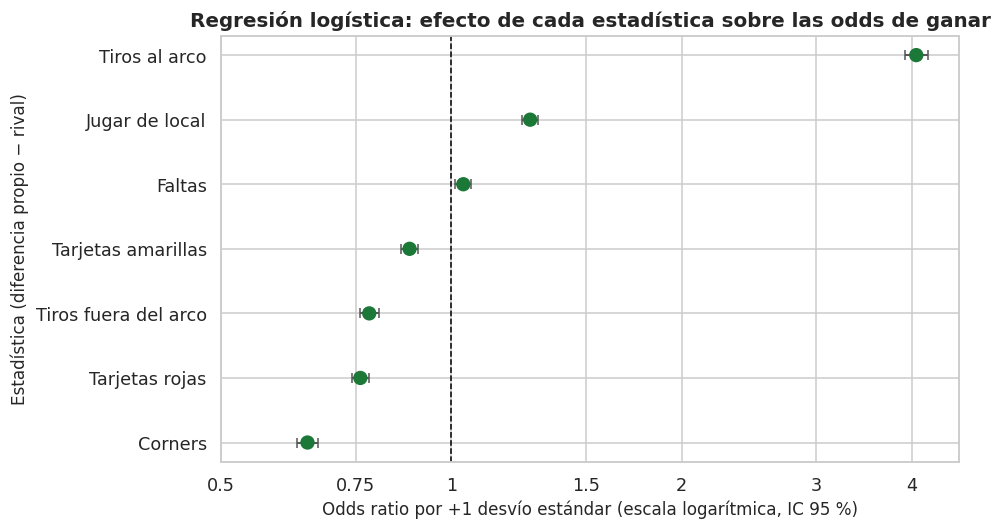

In [19]:
# Forest plot de odds ratios (por +1 desvío estándar de cada variable)
t = tabla_or.sort_values("OR_1SD")
y_pos = np.arange(len(t))
col = np.where(t["p_valor"] < 0.05, "#1b7837", "#7f7f7f")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(t["OR_1SD"], y_pos, xerr=[t["OR_1SD"] - t["IC95_inf"], t["IC95_sup"] - t["OR_1SD"]],
            fmt="none", ecolor="#555555", capsize=3, lw=1.3, zorder=2)
ax.scatter(t["OR_1SD"], y_pos, c=col, s=70, zorder=3)
ax.axvline(1, ls="--", color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_yticks(y_pos)
ax.set_yticklabels([NOMBRES[f] for f in t.index])
ax.set_xlabel("Odds ratio por +1 desvío estándar (escala logarítmica, IC 95 %)")
ax.set_ylabel("Estadística (diferencia propio − rival)")
ax.set_title("Regresión logística: efecto de cada estadística sobre las odds de ganar")
fig.tight_layout()
guardar_figura(fig, "g6_forest_odds_ratios")

**Interpretación (Gráfico 6).** Cada punto es el odds ratio de +1 desvío estándar; las barras son el IC 95 % (muy angostas por el tamaño de la muestra) y la línea punteada en 1 marca "sin efecto". Tiros al arco queda muy a la derecha del resto (OR ≈ 4,05), seguido a distancia por jugar de local (≈ 1,27). Corners, tiros fuera y rojas actúan en sentido contrario, y las faltas quedan casi sobre la línea de "sin efecto".

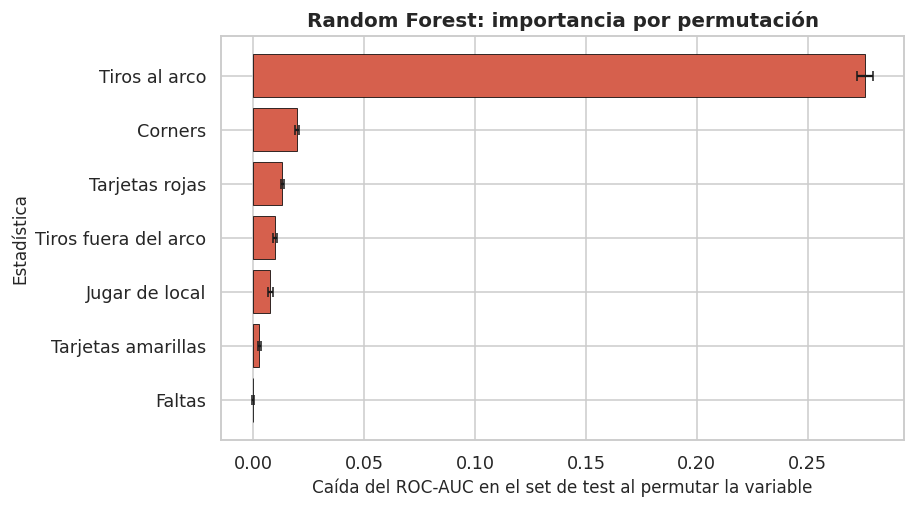

,media,desvio
Tiros al arco,0.2759,0.0037
Corners,0.0197,0.0010
Tarjetas rojas,0.0131,0.0007
Tiros fuera del arco,0.0098,0.0007
Jugar de local,0.0077,0.0011
Tarjetas amarillas,0.0028,0.0007
Faltas,-0.0002,0.0004


In [20]:
# Random Forest + importancia por permutación (caída del AUC al desordenar cada variable)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA).fit(X_tr, y_tr)
perm = permutation_importance(rf, X_te, y_te, n_repeats=10, scoring="roc_auc", random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({"media": perm.importances_mean, "desvio": perm.importances_std}, index=FEATURES).sort_values("media")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh([NOMBRES[f] for f in imp.index], imp["media"], xerr=imp["desvio"], color="#d6604d", capsize=3, edgecolor="black", lw=0.5)
ax.set_xlabel("Caída del ROC-AUC en el set de test al permutar la variable")
ax.set_ylabel("Estadística")
ax.set_title("Random Forest: importancia por permutación")
fig.tight_layout()
guardar_figura(fig, "g7_importancia_random_forest")
display(imp.sort_values("media", ascending=False).rename(index=NOMBRES).round(4))

**Interpretación (Gráfico 7).** El Random Forest, que no impone linealidad, coincide con la regresión: al desordenar los tiros al arco el AUC cae 0,276 puntos, unas 14 veces más que para cualquier otra variable (la segunda, corners, cae 0,020). Las faltas tienen importancia nula (≈ 0). Que dos métodos distintos converjan refuerza la conclusión.

In [21]:
# Evaluación en el set de test + validación cruzada agrupada
proba_lg = predecir_logit(modelo, X_te_s)
proba_rf = rf.predict_proba(X_te)[:, 1]
filas = []
for nombre, pr in [("Regresión logística", proba_lg), ("Random Forest", proba_rf)]:
    pred = (pr >= 0.5).astype(int)
    filas.append({"Modelo": nombre, "Accuracy": accuracy_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, pr)})
metricas = pd.DataFrame(filas).set_index("Modelo")
display(metricas.round(3))
print(f"Referencia: predecir siempre 'no victoria' daría accuracy = {1 - y_te.mean():.3f}")
print("Matriz de confusión (Regresión logística; filas = real, columnas = predicho):")
print(pd.DataFrame(confusion_matrix(y_te, (proba_lg >= .5).astype(int)), index=["No victoria", "Victoria"], columns=["No victoria", "Victoria"]).to_string())

cv = GroupKFold(n_splits=5)
pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000))
s = cross_val_score(pipe, X, y, groups=grupos, cv=cv, scoring="roc_auc")
print(f"\nValidación cruzada agrupada (5 pliegues), regresión logística: AUC = {s.mean():.3f} ± {s.std():.3f}")

tabla_or.to_csv(os.path.join(DIR_SALIDA, "tabla_odds_ratios.csv"), encoding="utf-8-sig")
metricas.to_csv(os.path.join(DIR_SALIDA, "metricas_modelos.csv"), encoding="utf-8-sig")

,Accuracy,ROC-AUC
Modelo,,
Regresión logística,0.745,0.806
Random Forest,0.743,0.803


Referencia: predecir siempre 'no victoria' daría accuracy = 0.626
Matriz de confusión (Regresión logística; filas = real, columnas = predicho):
             No victoria  Victoria
No victoria         8062      1376
Victoria            2476      3164

Validación cruzada agrupada (5 pliegues), regresión logística: AUC = 0.802 ± 0.004

**Interpretación de la evaluación.** En el set de prueba, ambos modelos clasifican correctamente cerca del 74,5 % de los equipo-partidos (accuracy 0,745 y 0,743), contra 62,6 % de un modelo trivial que siempre predijera "no victoria". El ROC-AUC es de 0,81 (0,5 sería azar) y la validación cruzada agrupada da 0,802 ± 0,004, o sea que el resultado es estable. El modelo es mejor detectando no-victorias que victorias: de las 5.640 victorias reales, detecta 3.164 (recall ≈ 56 %), y cuando predice victoria acierta ≈ 70 % de las veces. Es un desempeño bueno para un fenómeno con tanto azar como el fútbol, aunque lejos de ser perfecto. Regresión logística y Random Forest rinden casi igual, lo que sugiere que las relaciones son en esencia lineales y que no hay mucho por ganar con un modelo más complejo.

## Respuesta a la pregunta de investigación

**Pregunta:** ¿qué estadísticas de un partido se asocian más con la probabilidad de ganar?

**Respuesta:** entre las estadísticas disponibles, la que más se asocia con ganar es, por amplio margen, la **diferencia de tiros al arco con el rival**. Los equipos que ganan tiran al arco 6,0 veces por partido contra 3,7 de los que pierden; cada tiro al arco de ventaja aumenta las odds de ganar un 42 %; en el Random Forest explica más de 14 veces más capacidad predictiva que cualquier otra variable; y a nivel de temporada la ventaja en tiros al arco se correlaciona con los puntos obtenidos (r = 0,85). La **localía** es el segundo factor: jugar de local eleva las odds de ganar 1,61 veces aun a igualdad del resto de las estadísticas, aunque su peso decreció a lo largo de los 25 años (del 47,9 % al 42,7 % de victorias locales). Las **rojas** se asocian fuertemente con no ganar (probablemente en parte como consecuencia del mal desarrollo del partido), y **corners, tiros desviados, faltas y amarillas** aportan muy poco o van en sentido contrario una vez controlados los tiros al arco. La cantidad total de tiros no distingue a ganadores de perdedores; sí lo hace la calidad (tiros al arco). Los modelos clasifican bien el 74,5 % de los casos (AUC 0,81).

## Limitaciones y posibles extensiones
- **Faltan variables clave:** esta base no tiene **posesión**, xG, pases ni duelos. La posesión es una de las estadísticas más discutidas en el fútbol y no pudo evaluarse; incorporarla (por ejemplo desde FBref u otra fuente con datos reales) es la extensión más natural.
- **Cobertura desigual:** el 16 % de los partidos no tiene estadísticas (La Liga, Ligue 1 y Serie A antes de 2005/06, y la Bundesliga en 2002/03), así que las conclusiones se apoyan sobre todo en 2005/06–2024/25.
- **Asociación, no causalidad:** las estadísticas son de partido terminado y reflejan el estado del juego (el que gana suele replegarse y el que pierde presiona), lo que puede explicar los signos de corners, tiros fuera y rojas. Además, los tiros al arco están muy cerca de los goles, por lo que parte de su fuerza es casi mecánica.
- **No se controla la calidad de los equipos** (plantel, presupuesto) ni la liga o la época; el efecto de los tiros al arco podría combinar eficacia de juego y jerarquía del equipo.
- **"No victoria" mezcla empates y derrotas.** Un modelo de tres categorías (victoria / empate / derrota) daría una imagen más fina.